# 🔍 Detecção de Objetos com YOLOS-Small

Este notebook utiliza o modelo **[hustvl/yolos-small](https://huggingface.co/hustvl/yolos-small)** do HuggingFace para realizar detecção de objetos nas imagens da pasta `imagens/`.

**YOLOS** (You Only Look at One Sequence) é um detector de objetos baseado no Vision Transformer (ViT), treinado no dataset COCO (80 classes).

## 1. Importações e Configuração

In [18]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw, ImageFont
from transformers import AutoImageProcessor, AutoModelForObjectDetection

print(f"✅ Torch version: {torch.__version__}")
print(f"✅ CUDA disponível: {torch.cuda.is_available()}")
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"🖥️  Usando dispositivo: {DEVICE}")

✅ Torch version: 2.11.0+cpu
✅ CUDA disponível: False
🖥️  Usando dispositivo: cpu


## 2. Carregar Modelo e Processor

In [19]:
MODEL_NAME = "hustvl/yolos-small"

print(f"⬇️  Carregando modelo: {MODEL_NAME} ...")
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModelForObjectDetection.from_pretrained(MODEL_NAME)
model = model.to(DEVICE)
model.eval()

print(f"✅ Modelo carregado com sucesso!")
print(f"📋 Número de classes: {model.config.num_labels}")

# Exibir algumas classes disponíveis
id2label = model.config.id2label
print(f"🏷️  Algumas classes: {list(id2label.values())[:10]}...")

⬇️  Carregando modelo: hustvl/yolos-small ...


Loading weights: 100%|██████████| 212/212 [00:00<00:00, 7098.55it/s]

✅ Modelo carregado com sucesso!
📋 Número de classes: 91
🏷️  Algumas classes: ['N/A', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat']...


## 3. Funções Auxiliares

In [20]:
# Paleta de cores para as classes
np.random.seed(42)
COLORS = np.random.uniform(0, 255, size=(len(id2label), 3)).astype(int)

def detect_objects(image_path, confidence_threshold=0.4):
    """
    Realiza detecção de objetos em uma imagem.
    
    Args:
        image_path: Caminho para a imagem.
        confidence_threshold: Confiança mínima para considerar uma detecção.
    
    Returns:
        image: Imagem PIL original.
        results: Dicionário com boxes, scores e labels.
    """
    image = Image.open(image_path).convert("RGB")
    
    # Preprocessar
    inputs = processor(images=image, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    
    # Inferência
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Pós-processamento
    target_sizes = torch.tensor([image.size[::-1]])  # (height, width)
    results = processor.post_process_object_detection(
        outputs,
        threshold=confidence_threshold,
        target_sizes=target_sizes
    )[0]
    
    return image, results


def visualize_detections(image, results, image_name="", confidence_threshold=0.5):
    """
    Visualiza os resultados da detecção com bounding boxes coloridas.
    """
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    fig.patch.set_facecolor('#1a1a2e')
    
    # --- Painel esquerdo: imagem com bounding boxes ---
    ax_img = axes[0]
    ax_img.set_facecolor('#16213e')
    ax_img.imshow(image)
    ax_img.set_title(f'📷 {image_name}\nDetecções (threshold={confidence_threshold})',
                     color='white', fontsize=13, fontweight='bold', pad=10)
    ax_img.axis('off')
    
    boxes = results['boxes'].cpu().numpy()
    scores = results['scores'].cpu().numpy()
    labels = results['labels'].cpu().numpy()
    
    detection_summary = {}
    
    for box, score, label_id in zip(boxes, scores, labels):
        x1, y1, x2, y2 = box
        width = x2 - x1
        height = y2 - y1
        label_name = id2label[label_id]
        color = tuple(COLORS[label_id] / 255)
        
        # Desenhar bounding box
        rect = patches.FancyBboxPatch(
            (x1, y1), width, height,
            linewidth=2.5,
            edgecolor=color,
            facecolor=(*color, 0.08),
            boxstyle="round,pad=0"
        )
        ax_img.add_patch(rect)
        
        # Etiqueta com score
        label_text = f"{label_name}: {score:.2f}"
        ax_img.text(
            x1, y1 - 6, label_text,
            color='white', fontsize=9, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor=color, alpha=0.85, edgecolor='none')
        )
        
        # Acumular para resumo
        if label_name not in detection_summary:
            detection_summary[label_name] = []
        detection_summary[label_name].append(score)
    
    # --- Painel direito: gráfico de barras ---
    ax_bar = axes[1]
    ax_bar.set_facecolor('#16213e')
    
    if detection_summary:
        # Agrupar por classe: mostrar melhor score de cada
        class_names = list(detection_summary.keys())
        best_scores = [max(v) for v in detection_summary.values()]
        counts = [len(v) for v in detection_summary.values()]
        
        # Ordenar por score
        sorted_pairs = sorted(zip(best_scores, class_names, counts), reverse=True)
        best_scores, class_names, counts = zip(*sorted_pairs)
        
        bar_colors = [tuple(COLORS[list(id2label.values()).index(c)] / 255)
                      if c in list(id2label.values()) else (0.5, 0.5, 0.8)
                      for c in class_names]
        
        bars = ax_bar.barh(class_names, best_scores, color=bar_colors,
                           edgecolor='white', linewidth=0.5, height=0.6)
        
        # Anotações nas barras
        for bar, score, count in zip(bars, best_scores, counts):
            ax_bar.text(
                bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
                f"{score:.2f}  (x{count})",
                va='center', ha='left', color='white', fontsize=10, fontweight='bold'
            )
        
        ax_bar.set_xlim(0, 1.25)
        ax_bar.set_xlabel('Confiança', color='white', fontsize=11)
        ax_bar.set_title('📊 Classes Detectadas\n(melhor score por classe)',
                         color='white', fontsize=13, fontweight='bold', pad=10)
        ax_bar.tick_params(colors='white')
        ax_bar.spines['bottom'].set_color('#444')
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        ax_bar.spines['left'].set_color('#444')
        ax_bar.set_facecolor('#16213e')
        ax_bar.axvline(x=confidence_threshold, color='#ff6b6b', linestyle='--',
                       linewidth=1.5, label=f'Threshold ({confidence_threshold})')
        ax_bar.legend(facecolor='#16213e', edgecolor='#444', labelcolor='white', fontsize=9)
    else:
        ax_bar.text(0.5, 0.5, '⚠️ Nenhum objeto\ndetectado acima\ndo threshold',
                    ha='center', va='center', color='#ff6b6b',
                    fontsize=14, transform=ax_bar.transAxes)
        ax_bar.set_title('📊 Classes Detectadas', color='white', fontsize=13, fontweight='bold')
    
    plt.tight_layout(pad=2)
    plt.show()
    
    return detection_summary

print("✅ Funções auxiliares definidas!")

✅ Funções auxiliares definidas!


## 4. Listar Imagens Disponíveis

In [21]:
IMAGES_DIR = "imagens"
CONFIDENCE_THRESHOLD = 0.5

# Buscar todas as imagens
extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.webp']
image_paths = []
for ext in extensions:
    image_paths.extend(glob.glob(os.path.join(IMAGES_DIR, ext)))
    image_paths.extend(glob.glob(os.path.join(IMAGES_DIR, ext.upper())))

image_paths = sorted(set(image_paths))

print(f"📁 Pasta: ./{IMAGES_DIR}/")
print(f"🖼️  Total de imagens encontradas: {len(image_paths)}")
print()
for i, path in enumerate(image_paths):
    img = Image.open(path)
    size_kb = os.path.getsize(path) / 1024
    print(f"  [{i+1}] {os.path.basename(path):25s} | {img.size[0]}x{img.size[1]} px | {size_kb:.0f} KB")

📁 Pasta: ./imagens/
🖼️  Total de imagens encontradas: 4

  [1] bird.jpg                  | 4386x2924 px | 1747 KB
  [2] cats_dog.png              | 1000x563 px | 693 KB
  [3] kitchen.png               | 740x493 px | 497 KB
  [4] pizza.png                 | 1024x969 px | 595 KB


## 5. Detecção em Todas as Imagens


🔍 Processando: bird.jpg
   ✔ 1 objeto(s) detectado(s) acima de 0.5
   → bird: 1.00


C:\Users\felip\AppData\Local\Temp\ipykernel_23448\4213341675.py:137: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(pad=2)
C:\Users\felip\AppData\Local\Temp\ipykernel_23448\4213341675.py:137: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout(pad=2)


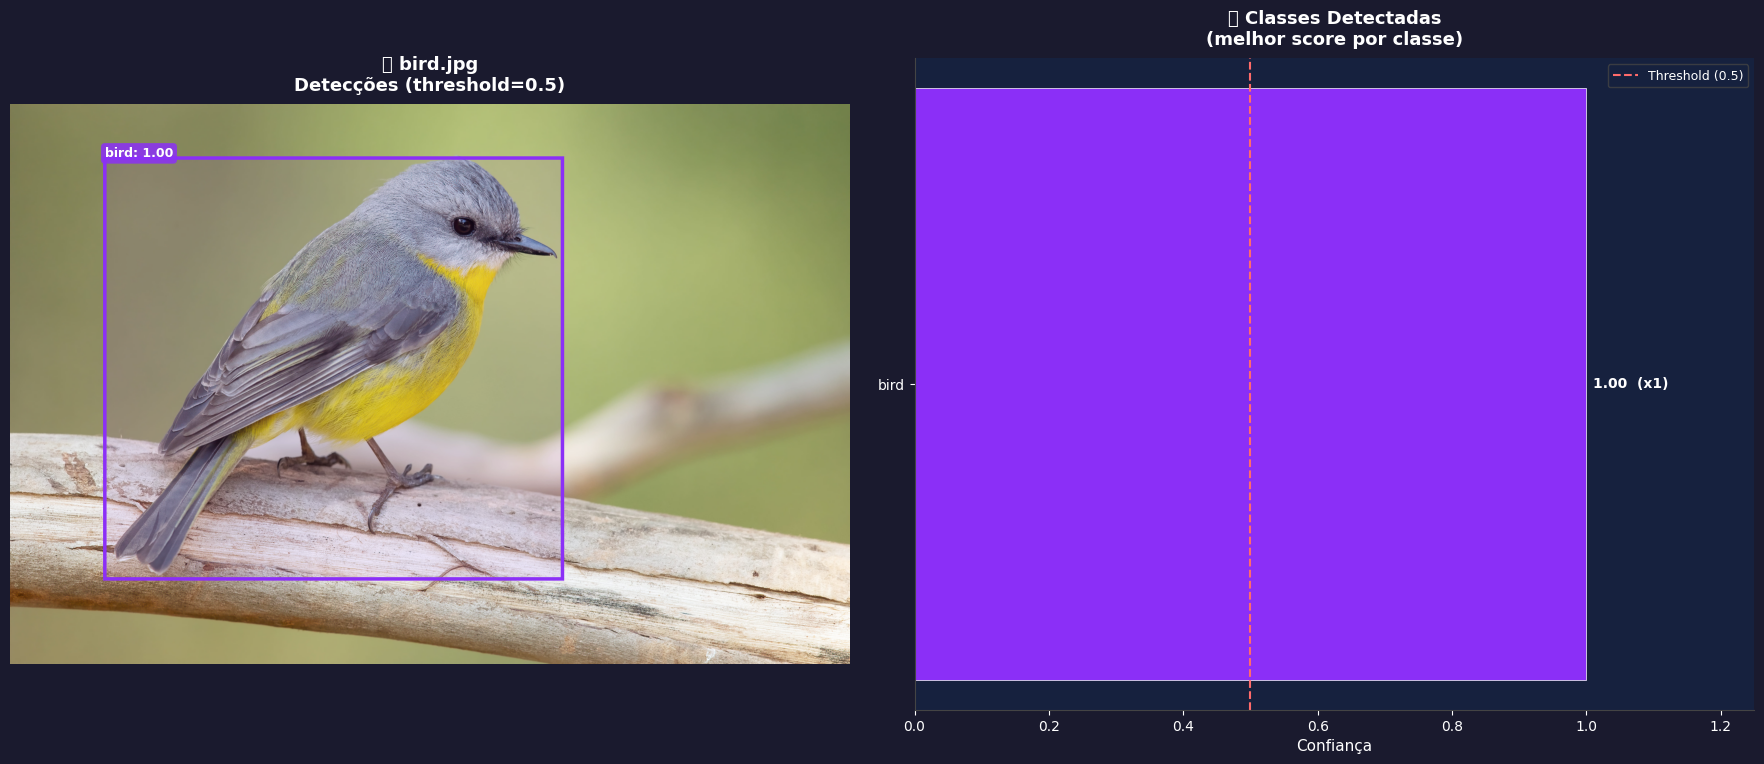


🔍 Processando: cats_dog.png
   ✔ 5 objeto(s) detectado(s) acima de 0.5
   → cat: 1.00
   → dog: 0.99
   → bed: 0.61
   → cat: 0.79
   → bed: 0.79


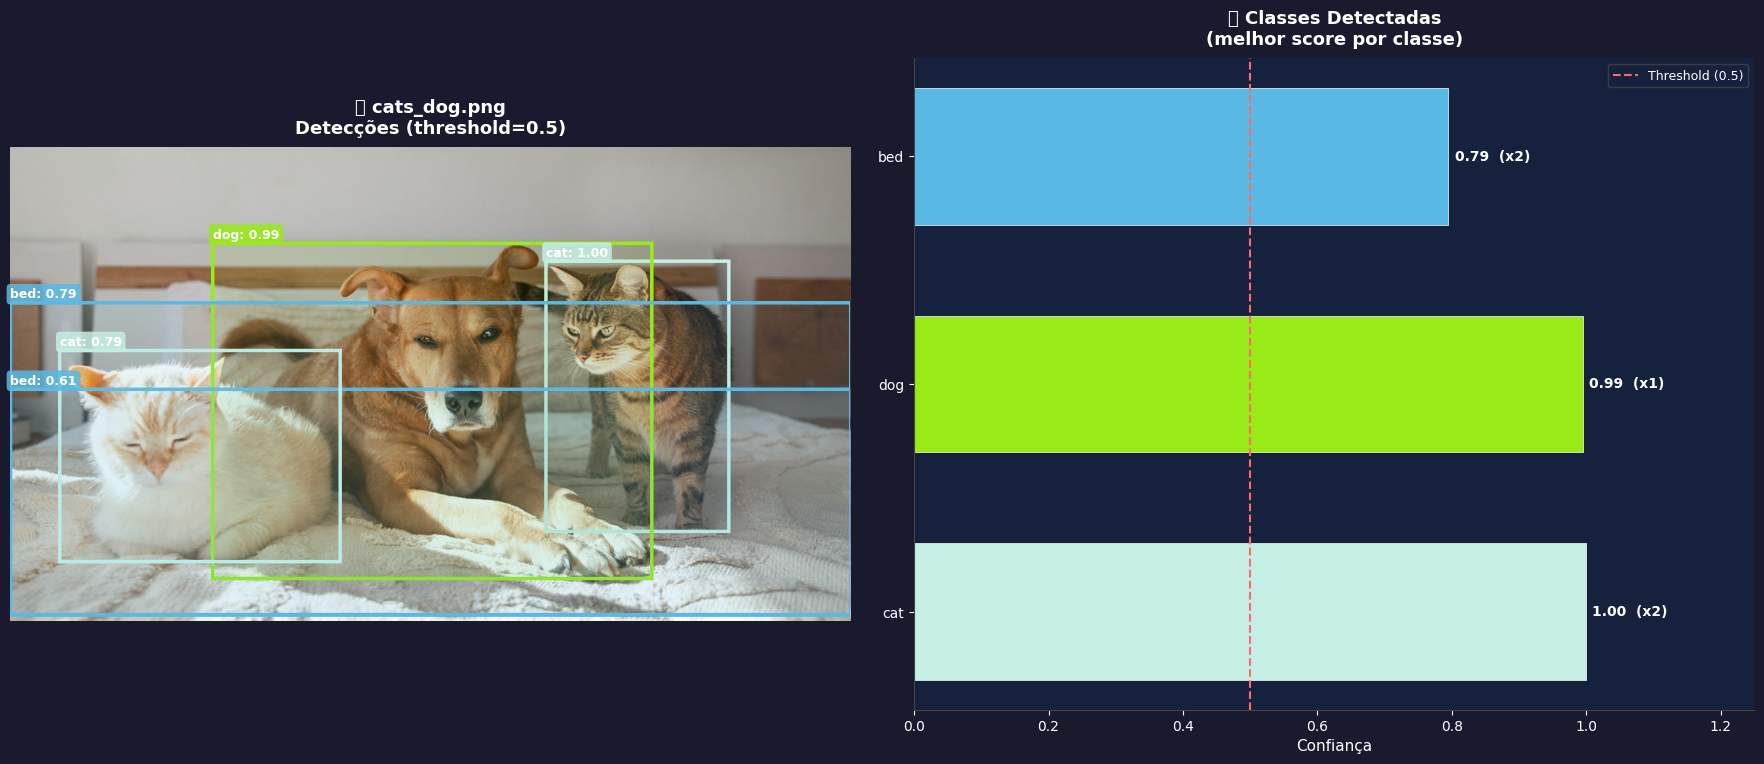


🔍 Processando: kitchen.png
   ✔ 15 objeto(s) detectado(s) acima de 0.5
   → bowl: 0.50
   → vase: 0.94
   → spoon: 0.54
   → potted plant: 0.81
   → vase: 0.97
   → potted plant: 0.76
   → bottle: 0.92
   → bowl: 0.65
   → potted plant: 0.93
   → oven: 0.95
   → vase: 0.52
   → refrigerator: 0.84
   → bowl: 0.58
   → bowl: 0.94
   → potted plant: 0.76


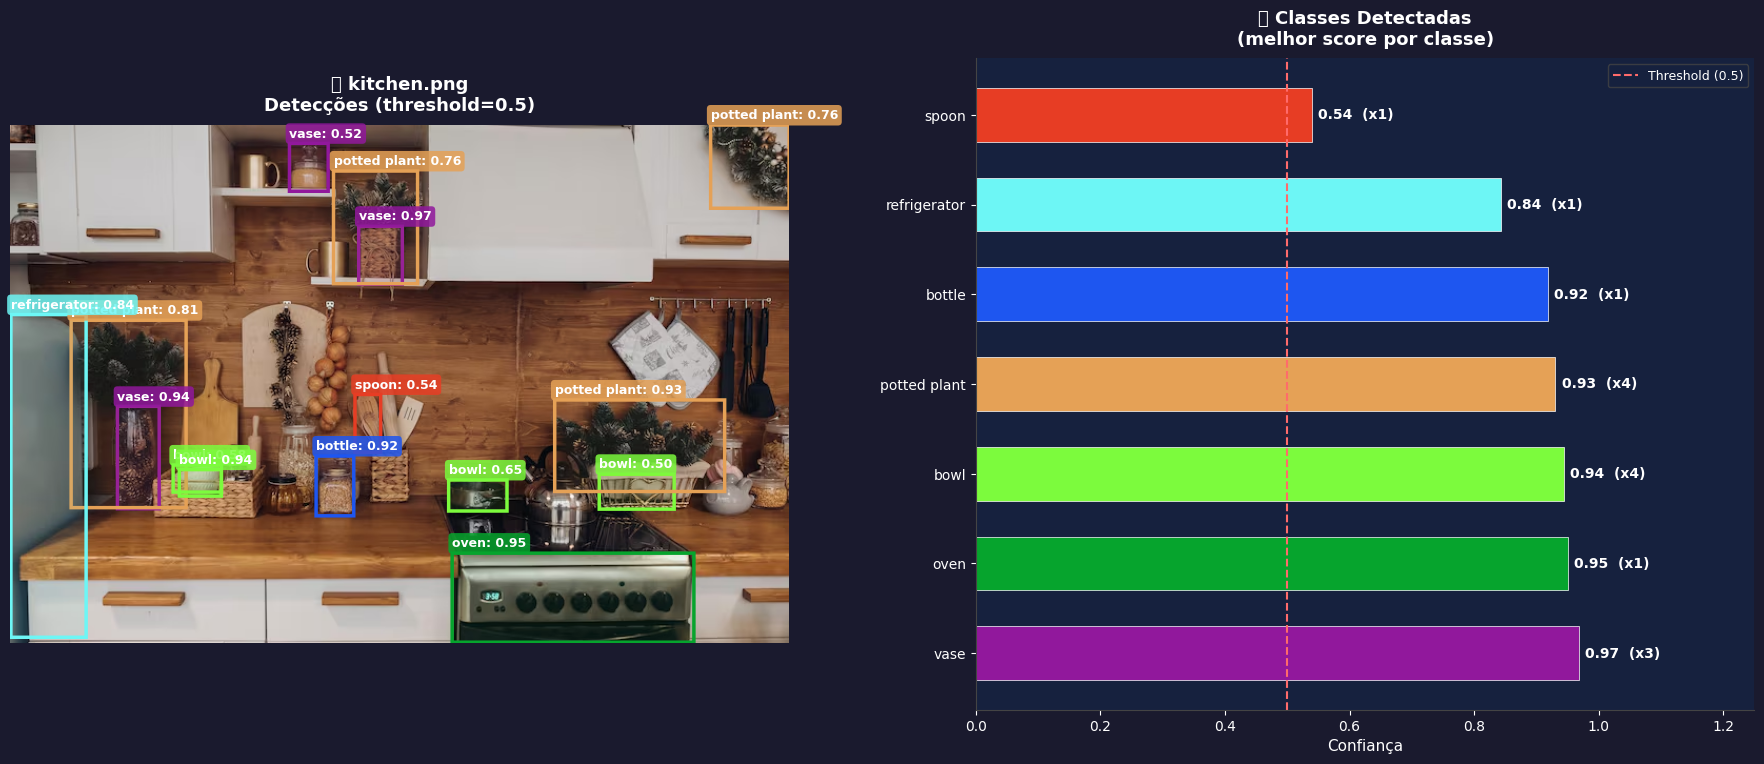


🔍 Processando: pizza.png
   ✔ 9 objeto(s) detectado(s) acima de 0.5
   → pizza: 0.78
   → pizza: 0.52
   → pizza: 0.60
   → pizza: 0.91
   → pizza: 0.88
   → pizza: 0.81
   → pizza: 0.98
   → pizza: 0.66
   → pizza: 0.60


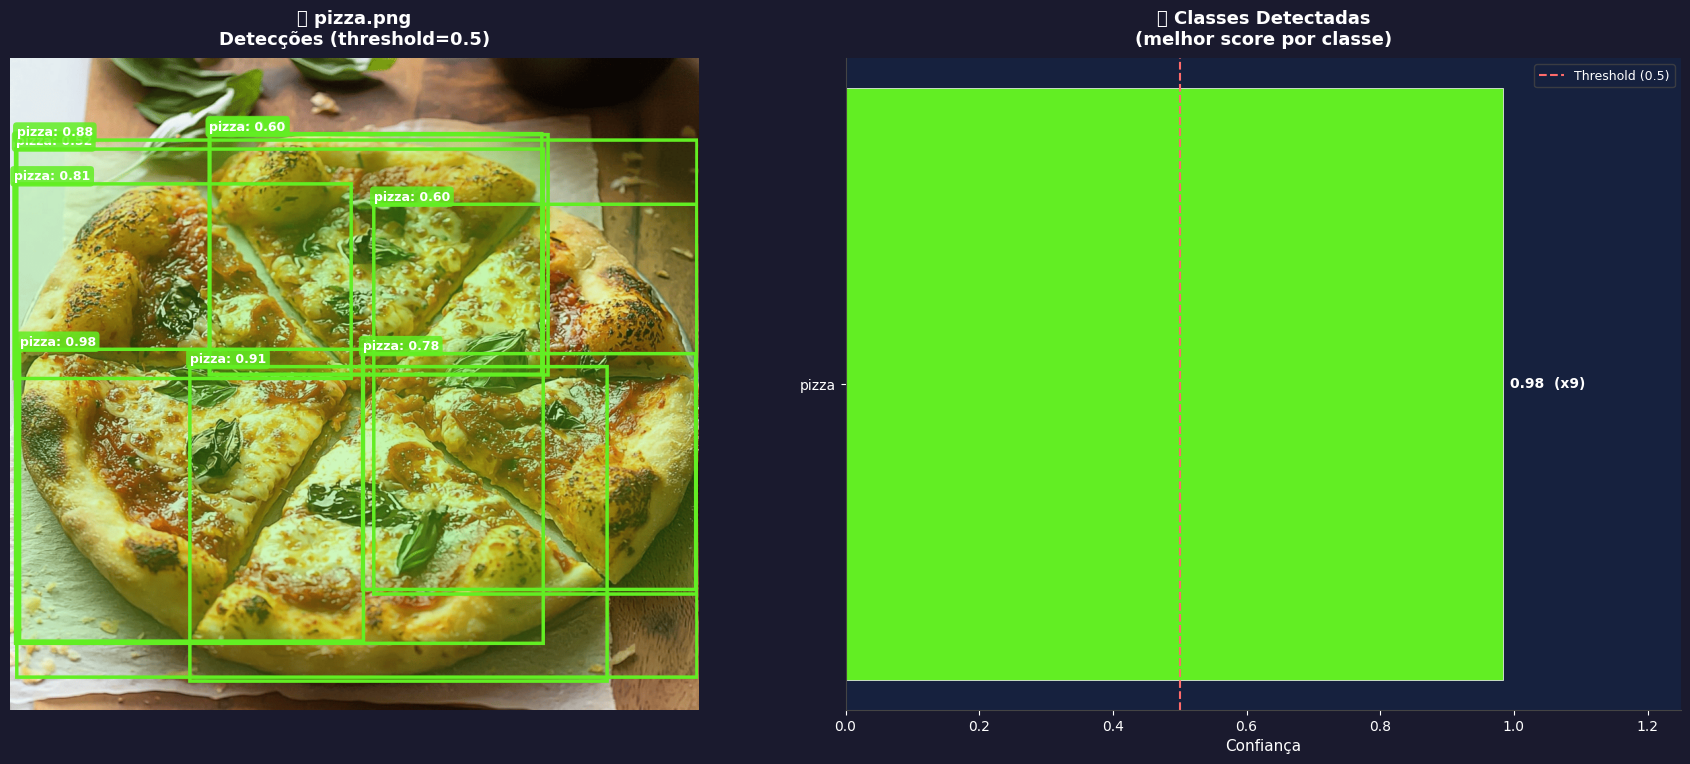

In [22]:
all_results = {}

for image_path in image_paths:
    img_name = os.path.basename(image_path)
    print(f"\n{'='*60}")
    print(f"🔍 Processando: {img_name}")
    print(f"{'='*60}")
    
    image, results = detect_objects(image_path, confidence_threshold=CONFIDENCE_THRESHOLD)
    
    n_detections = len(results['scores'])
    print(f"   ✔ {n_detections} objeto(s) detectado(s) acima de {CONFIDENCE_THRESHOLD}")
    
    if n_detections > 0:
        labels_found = [id2label[l.item()] for l in results['labels']]
        scores_found = [f"{s:.2f}" for s in results['scores']]
        for lbl, sc in zip(labels_found, scores_found):
            print(f"   → {lbl}: {sc}")
    
    summary = visualize_detections(image, results, image_name=img_name,
                                   confidence_threshold=CONFIDENCE_THRESHOLD)
    all_results[img_name] = {
        'n_detections': n_detections,
        'summary': summary
    }

## 6. Resumo Geral das Detecções


📊 RESUMO GERAL DAS DETECÇÕES

  🖼️  bird.jpg: 1 objeto(s)
      • bird (x1) → melhor: 1.00

  🖼️  cats_dog.png: 5 objeto(s)
      • cat (x2) → melhor: 1.00
      • dog (x1) → melhor: 0.99
      • bed (x2) → melhor: 0.79

  🖼️  kitchen.png: 15 objeto(s)
      • bowl (x4) → melhor: 0.94
      • vase (x3) → melhor: 0.97
      • spoon (x1) → melhor: 0.54
      • potted plant (x4) → melhor: 0.93
      • bottle (x1) → melhor: 0.92
      • oven (x1) → melhor: 0.95
      • refrigerator (x1) → melhor: 0.84

  🖼️  pizza.png: 9 objeto(s)
      • pizza (x9) → melhor: 0.98

  Total de objetos detectados: 30
  Classes únicas encontradas: 12



C:\Users\felip\AppData\Local\Temp\ipykernel_23448\1807062173.py:49: UserWarning: Glyph 127757 (\N{EARTH GLOBE EUROPE-AFRICA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


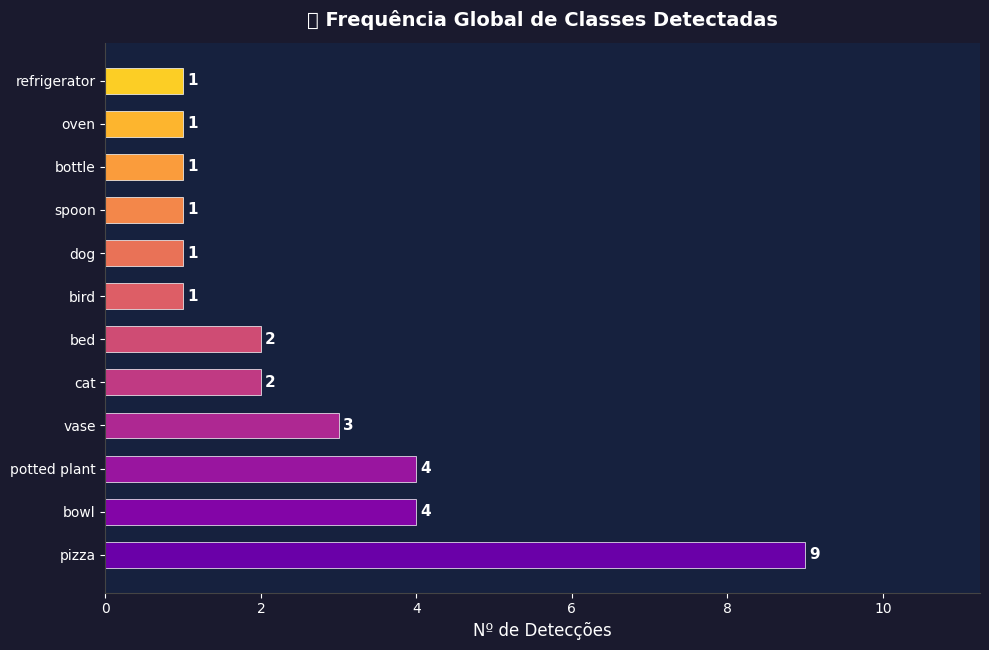

In [23]:
print("\n" + "="*60)
print("📊 RESUMO GERAL DAS DETECÇÕES")
print("="*60)

total_objs = 0
global_classes = {}

for img_name, data in all_results.items():
    n = data['n_detections']
    total_objs += n
    print(f"\n  🖼️  {img_name}: {n} objeto(s)")
    for cls, scores in data['summary'].items():
        print(f"      • {cls} (x{len(scores)}) → melhor: {max(scores):.2f}")
        global_classes[cls] = global_classes.get(cls, 0) + len(scores)

print(f"\n{'='*60}")
print(f"  Total de objetos detectados: {total_objs}")
print(f"  Classes únicas encontradas: {len(global_classes)}")
print()

# Gráfico de frequência global
if global_classes:
    fig, ax = plt.subplots(figsize=(10, max(4, len(global_classes) * 0.55)))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')
    
    sorted_classes = sorted(global_classes.items(), key=lambda x: x[1], reverse=True)
    cls_names, cls_counts = zip(*sorted_classes)
    
    bar_colors = plt.cm.plasma(np.linspace(0.2, 0.9, len(cls_names)))
    bars = ax.barh(cls_names, cls_counts, color=bar_colors, edgecolor='white',
                   linewidth=0.5, height=0.6)
    
    for bar, count in zip(bars, cls_counts):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
                str(count), va='center', ha='left', color='white',
                fontsize=11, fontweight='bold')
    
    ax.set_xlim(0, max(cls_counts) * 1.25)
    ax.set_xlabel('Nº de Detecções', color='white', fontsize=12)
    ax.set_title('🌍 Frequência Global de Classes Detectadas',
                 color='white', fontsize=14, fontweight='bold', pad=12)
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_color('#444')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()